# Meteo data - hourly

In [2]:
import pandas as pd
import os
from utils import read_files
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# this folder is not on GitHub, because it's too large
path = "data/ugz_meteo_h1/"

files_meteo = os.listdir(path)

for i in range(len(files_meteo)):
    files_meteo[i] = os.path.join(path, files_meteo[i])

df_meteo = read_files(file_paths=files_meteo, drop_columns=["Intervall", "Status"], date_column="Datum")#, UTC=False)

columns_meteo = df_meteo.columns

#df_meteo = df_meteo.drop(columns=[columns_meteo[3], columns_meteo[6], columns_meteo[8]])
columns_meteo = df_meteo.columns
#print(columns_meteo)
df_meteo

,Datum,Standort,Parameter,Einheit,Wert,Year,Datetime
0,2017-01-01T00:00+0100,Zch_Rosengartenstrasse,Hr,%Hr,88.22,2017,2017-01-01 00:00:00+01:00
1,2017-01-01T00:00+0100,Zch_Rosengartenstrasse,RainDur,min,0.00,2017,2017-01-01 00:00:00+01:00
2,2017-01-01T00:00+0100,Zch_Rosengartenstrasse,T,°C,-1.73,2017,2017-01-01 00:00:00+01:00
3,2017-01-01T00:00+0100,Zch_Rosengartenstrasse,WD,°,194.17,2017,2017-01-01 00:00:00+01:00
4,2017-01-01T00:00+0100,Zch_Rosengartenstrasse,WVv,m/s,0.32,2017,2017-01-01 00:00:00+01:00
...,...,...,...,...,...,...,...
1748422,2025-12-30T07:00+0100,Zch_Stampfenbachstrasse,T,°C,-1.26,2025,2025-12-30 07:00:00+01:00
1748423,2025-12-30T07:00+0100,Zch_Stampfenbachstrasse,WD,°,52.52,2025,2025-12-30 07:00:00+01:00
1748424,2025-12-30T07:00+0100,Zch_Stampfenbachstrasse,WVs,m/s,1.54,2025,2025-12-30 07:00:00+01:00
1748425,2025-12-30T07:00+0100,Zch_Stampfenbachstrasse,WVv,m/s,1.47,2025,2025-12-30 07:00:00+01:00


In [4]:
#station_map = {
#    "Rosengartenstrasse (Nordstrasse)": "Zch_Rosengartenstrasse",
#    "Stampfenbachstrasse (Wasserwerkstrasse)": "Zch_Stampfenbachstrasse",
#    "Schimmelstrasse (Werdstrasse)": "Zch_Schimmelstrasse",
#    "Zürichbergstrasse (Dreiwiesenstrasse)": "Zch_Heubeeribüel"
#}

In [5]:
#df_meteo = df_meteo[df_meteo["Standort"].isin(station_map)]

In [6]:
#df_meteo["pollutant_station"] = df_meteo["Standort"]#.map(station_map)

In [7]:
df_meteo.head()

,Datum,Standort,Parameter,Einheit,Wert,Year,Datetime
0,2017-01-01T00:00+0100,Zch_Rosengartenstrasse,Hr,%Hr,88.22,2017,2017-01-01 00:00:00+01:00
1,2017-01-01T00:00+0100,Zch_Rosengartenstrasse,RainDur,min,0.00,2017,2017-01-01 00:00:00+01:00
2,2017-01-01T00:00+0100,Zch_Rosengartenstrasse,T,°C,-1.73,2017,2017-01-01 00:00:00+01:00
3,2017-01-01T00:00+0100,Zch_Rosengartenstrasse,WD,°,194.17,2017,2017-01-01 00:00:00+01:00
4,2017-01-01T00:00+0100,Zch_Rosengartenstrasse,WVv,m/s,0.32,2017,2017-01-01 00:00:00+01:00


In [8]:
param_units_meteo = (
    df_meteo[["Parameter", "Einheit"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

param_units_meteo

,Parameter,Einheit
0,Hr,%Hr
1,RainDur,min
2,T,°C
3,WD,°
4,WVv,m/s
5,p,hPa
6,WVs,m/s
7,StrGlo,W/m2


In [9]:
# --- 1) Parse datetime and split date/time ---
df_meteo["Datetime"] = pd.to_datetime(df_meteo["Datetime"], errors="coerce")
df_meteo["Datum_date"] = df_meteo["Datetime"].dt.date   # Python date objects
df_meteo["Datum_time"] = df_meteo["Datetime"].dt.time   # Python time objects

df_meteo

,Datum,Standort,Parameter,Einheit,Wert,Year,Datetime,Datum_date,Datum_time
0,2017-01-01T00:00+0100,Zch_Rosengartenstrasse,Hr,%Hr,88.22,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00
1,2017-01-01T00:00+0100,Zch_Rosengartenstrasse,RainDur,min,0.00,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00
2,2017-01-01T00:00+0100,Zch_Rosengartenstrasse,T,°C,-1.73,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00
3,2017-01-01T00:00+0100,Zch_Rosengartenstrasse,WD,°,194.17,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00
4,2017-01-01T00:00+0100,Zch_Rosengartenstrasse,WVv,m/s,0.32,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00
...,...,...,...,...,...,...,...,...,...
1748422,2025-12-30T07:00+0100,Zch_Stampfenbachstrasse,T,°C,-1.26,2025,2025-12-30 07:00:00+01:00,2025-12-30,07:00:00
1748423,2025-12-30T07:00+0100,Zch_Stampfenbachstrasse,WD,°,52.52,2025,2025-12-30 07:00:00+01:00,2025-12-30,07:00:00
1748424,2025-12-30T07:00+0100,Zch_Stampfenbachstrasse,WVs,m/s,1.54,2025,2025-12-30 07:00:00+01:00,2025-12-30,07:00:00
1748425,2025-12-30T07:00+0100,Zch_Stampfenbachstrasse,WVv,m/s,1.47,2025,2025-12-30 07:00:00+01:00,2025-12-30,07:00:00


In [10]:
# Pivot with split date and time columns

# 1) Parse 'Datum' as timezone-aware datetime
# Pandas can parse 'YYYY-MM-DDTHH:MM+0100' directly.
df_meteo["Datetime"] = pd.to_datetime(df_meteo["Datum"], errors="coerce")

# 2) Create date and time columns
df_meteo["Datum_date"] = df_meteo["Datetime"].dt.date      # dtype: object (date objects)
df_meteo["Datum_time"] = df_meteo["Datetime"].dt.time      # dtype: object (time objects)
# Optional: if you prefer pure pandas dtypes (no Python date/time objects),
# you can keep them as strings or as datetime64:
# df_meteo["Datum_date"] = df_meteo["Datum"].dt.strftime("%Y-%m-%d")
# df_meteo["Datum_time"] = df_meteo["Datum"].dt.strftime("%H:%M:%S%z")

# 3) Now pivot using the original 'Datum' or the split columns as needed
df_meteo_pivot = df_meteo.pivot(
    #index=["Datum", "Standort"], 
    index = ['Year', 'Datetime', 'Datum_date','Datum_time','Standort'], # you can also use ['Datum_date','Datum_time','Standort']
    columns="Parameter",
    values="Wert"
)


# --- 3) Drop unwanted pollutant columns (if present) ---
cols_to_drop = ["CO", "O3_max_h1", "O3_nb_h1>120", "SO2", "PN"]
df_meteo_pivot = df_meteo_pivot.drop(
    columns=[c for c in cols_to_drop if c in df_meteo_pivot.columns],
    errors="ignore"
)

# --- 4) Remove the column index name ('Parameter') immediately ---
df_meteo_pivot.columns.name = None

# --- 5) Reset index so keys become columns (flat DataFrame) ---
df_meteo_pivot = df_meteo_pivot.reset_index()   # unfortunately this is needed, otherwise the parameter names are in separate row

# At this point, df_meteo_pivot has columns:
# ['Datum_date', 'Datum_time', 'Standort', 'NO', 'NO2', 'NOx', 'O3', 'PM10', 'PM2.5', ...]
# with NO extra header name for the pollutant columns.
df_meteo_pivot

,Year,Datetime,Datum_date,Datum_time,Standort,Hr,RainDur,StrGlo,T,WD,WVs,WVv,p
0,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00,Zch_Rosengartenstrasse,88.22,0.0,NaN,-1.73,194.17,0.36,0.32,977.84
1,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00,Zch_Schimmelstrasse,84.78,0.0,NaN,-1.33,337.53,NaN,0.99,980.34
2,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00,Zch_Stampfenbachstrasse,87.41,0.0,0.03,-1.65,292.05,1.36,1.36,977.22
3,2017,2017-01-01 01:00:00+01:00,2017-01-01,01:00:00,Zch_Rosengartenstrasse,88.35,0.0,NaN,-2.06,145.18,0.22,0.22,977.24
4,2017,2017-01-01 01:00:00+01:00,2017-01-01,01:00:00,Zch_Schimmelstrasse,83.94,0.0,NaN,-1.61,341.51,NaN,0.85,979.76
...,...,...,...,...,...,...,...,...,...,...,...,...,...
254043,2025,2025-12-30 06:00:00+01:00,2025-12-30,06:00:00,Zch_Stampfenbachstrasse,76.10,0.0,0.02,-1.27,308.60,0.63,0.19,971.46
254044,2025,2025-12-30 07:00:00+01:00,2025-12-30,07:00:00,Zch_Heubeeribüel,98.58,NaN,NaN,-3.93,NaN,NaN,NaN,950.67
254045,2025,2025-12-30 07:00:00+01:00,2025-12-30,07:00:00,Zch_Rosengartenstrasse,78.31,0.0,NaN,-1.65,65.73,0.35,0.20,971.97
254046,2025,2025-12-30 07:00:00+01:00,2025-12-30,07:00:00,Zch_Schimmelstrasse,79.60,0.0,NaN,-0.65,346.78,0.60,0.07,974.56


In [11]:
desired_order = ["Year", "Datetime", "Datum_date", "Datum_time", "Standort"]
df_meteo_pivot = df_meteo_pivot[desired_order + [col for col in df_meteo_pivot.columns if col not in desired_order]]
df_meteo_pivot.head()

,Year,Datetime,Datum_date,Datum_time,Standort,Hr,RainDur,StrGlo,T,WD,WVs,WVv,p
0,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00,Zch_Rosengartenstrasse,88.22,0.0,NaN,-1.73,194.17,0.36,0.32,977.84
1,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00,Zch_Schimmelstrasse,84.78,0.0,NaN,-1.33,337.53,NaN,0.99,980.34
2,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00,Zch_Stampfenbachstrasse,87.41,0.0,0.03,-1.65,292.05,1.36,1.36,977.22
3,2017,2017-01-01 01:00:00+01:00,2017-01-01,01:00:00,Zch_Rosengartenstrasse,88.35,0.0,NaN,-2.06,145.18,0.22,0.22,977.24
4,2017,2017-01-01 01:00:00+01:00,2017-01-01,01:00:00,Zch_Schimmelstrasse,83.94,0.0,NaN,-1.61,341.51,NaN,0.85,979.76


In [12]:
# Display df_pollutants info and missing values
print("df_meteo shape:", df_meteo_pivot.shape)
print("\nMissing values per column:")
print(df_meteo_pivot.isnull().sum())
print("\nData types:")
print(df_meteo_pivot.dtypes)

df_meteo shape: (254048, 13)

Missing values per column:
Year               0
Datetime           0
Datum_date         0
Datum_time         0
Standort           0
Hr              5199
RainDur        19867
StrGlo        175305
T               3133
WD             21495
WVs            58518
WVv            21495
p               2845
dtype: int64

Data types:
Year                              int64
Datetime      datetime64[ns, UTC+01:00]
Datum_date                       object
Datum_time                       object
Standort                         object
Hr                              float64
RainDur                         float64
StrGlo                          float64
T                               float64
WD                              float64
WVs                             float64
WVv                             float64
p                               float64
dtype: object


In [13]:
# --- Identify key and parameter columns ---
key_cols = [c for c in ["Standort", "Datum_date", "Datum_time"] if c in df_meteo_pivot.columns]
pollutant_cols = [c for c in df_meteo_pivot.columns if c not in key_cols]

if "Standort" not in key_cols:
    raise KeyError("Column 'Standort' must be present for station-level summaries.")
if "Datum_date" not in key_cols:
    raise KeyError("Column 'Datum_date' is required (date-only).")

# Ensure date-only type for coverage stats
df_meteo_pivot["Datum_date"] = pd.to_datetime(df_meteo_pivot["Datum_date"], errors="coerce").dt.date
# --- Station-level base coverage: rows & date span ---
base = (df_meteo_pivot
        .groupby("Standort", as_index=True)
        .agg(n_rows=("Standort", "size"),
             n_days=("Datum_date", "nunique"),
             min_date=("Datum_date", "min"),
             max_date=("Datum_date", "max")))

# --- Missing counts per pollutant (per station) ---
miss_by_station = (df_meteo_pivot[pollutant_cols]
                   .isna()
                   .groupby(df_meteo_pivot["Standort"])
                   .sum())

# --- Missing rates per pollutant (divide by the station's row count) ---
#miss_rate_by_station = miss_by_station.div(base["n_rows"], axis=0)

# --- Combined wide summary (counts + rates, alongside coverage) ---
summary_wide = (base
                .join(miss_by_station.add_prefix("miss_"))
                #.join(miss_rate_by_station.add_prefix("rate_"))
               )

print("\nStation-level summary (counts):")# & rates):")
print(summary_wide)  # Each station: n_rows, n_days, min/max date, miss_* and rate_* per pollutant



Station-level summary (counts):
                         n_rows  n_days    min_date    max_date  miss_Year  \
Standort                                                                     
Zch_Heubeeribüel          17504     730  2024-01-01  2025-12-30          0   
Zch_Rosengartenstrasse    78848    3286  2017-01-01  2025-12-30          0   
Zch_Schimmelstrasse       78848    3286  2017-01-01  2025-12-30          0   
Zch_Stampfenbachstrasse   78848    3286  2017-01-01  2025-12-30          0   

                         miss_Datetime  miss_Hr  miss_RainDur  miss_StrGlo  \
Standort                                                                     
Zch_Heubeeribüel                     0        7         17504        17504   
Zch_Rosengartenstrasse               0     1989          1437        78848   
Zch_Schimmelstrasse                  0     2796           826        78848   
Zch_Stampfenbachstrasse              0      407           100          105   

                         miss

In [14]:
# --- Identify key and pollutant columns ---
key_cols = [c for c in ["Standort", "Datum_date", "Datum_time"] if c in df_meteo_pivot.columns]
parameters_cols = [c for c in df_meteo_pivot.columns if c not in key_cols]

if "Standort" not in key_cols:
    raise KeyError("Column 'Standort' must be present for station-level summaries.")
if "Datum_date" not in key_cols:
    raise KeyError("Column 'Datum_date' is required (date-only key).")

# --- Ensure date type and derive year ---
# (Works whether Datum_date is a string, datetime.date, or Timestamp.)
df_meteo_pivot = df_meteo_pivot.copy()
df_meteo_pivot["Datum_date"] = pd.to_datetime(df_meteo_pivot["Datum_date"], errors="coerce")
#df_meteo_pivot["Year"] = df_meteo_pivot["Datum_date"].dt.year

# Drop rows where year couldn't be parsed (optional)
dfp = df_meteo_pivot.dropna(subset=["Year"]).copy()

# --- Base coverage per (Station, Year) ---
base_year = (dfp
    .groupby(["Standort", "Year"], as_index=True)
    .agg(
        n_rows=("Standort", "size"),              # total rows (daily or hourly)
        n_days=("Datum_date", "nunique"),         # number of distinct days
        min_date=("Datum_date", "min"),
        max_date=("Datum_date", "max"),
    )
)

# --- Missing counts per pollutant per (Station, Year) ---
miss_by_station_year = (dfp[parameters_cols]
    .isna()
    .groupby([dfp["Standort"], dfp["Year"]])     # use Series as grouper
    .sum()
)

# --- Missing rates (divide by n_rows per (Station, Year)) ---
#miss_rate_by_station_year = miss_by_station_year.div(base_year["n_rows"], axis=0)

# --- Wide summary: coverage + missing counts + missing rates ---
summary_wide_year = (base_year
    .join(miss_by_station_year.add_prefix("miss_"))
   # .join(miss_rate_by_station_year.add_prefix("rate_"))
)

print("\nStation-level summary per year (wide):")
print(summary_wide_year)  # MultiIndex rows: (Standort, Year)

# UNCOMMENT TO GET RELATIVE MISSING RATES AS TIDY DATAFRAME

# --- Tidy summary: one row per (Station, Year, Pollutant) with counts & rates ---
#miss_tidy_year = (miss_by_station_year
#    .reset_index()
#    .melt(id_vars=["Standort", "Year"], var_name="Parameter", value_name="missing_count")
#)

#miss_tidy_year = miss_tidy_year.merge(
#    base_year["n_rows"].rename("n_rows").reset_index(),
#    on=["Standort", "Year"],
#    how="left"
#)
#miss_tidy_year["missing_rate"] = miss_tidy_year["missing_count"] / miss_tidy_year["n_rows"]
#miss_tidy_year = miss_tidy_year.sort_values(["Standort", "Year", "Parameter"]).reset_index(drop=True)
#print("\nTidy station-year-pollutant NA summary:")
#print(miss_tidy_year.head(20))


Station-level summary per year (wide):
                              n_rows  n_days   min_date   max_date  miss_Year  \
Standort                Year                                                    
Zch_Heubeeribüel        2024    8784     366 2024-01-01 2024-12-31          0   
                        2025    8720     364 2025-01-01 2025-12-30          0   
Zch_Rosengartenstrasse  2017    8760     365 2017-01-01 2017-12-31          0   
                        2018    8760     365 2018-01-01 2018-12-31          0   
                        2019    8760     365 2019-01-01 2019-12-31          0   
                        2020    8784     366 2020-01-01 2020-12-31          0   
                        2021    8760     365 2021-01-01 2021-12-31          0   
                        2022    8760     365 2022-01-01 2022-12-31          0   
                        2023    8760     365 2023-01-01 2023-12-31          0   
                        2024    8784     366 2024-01-01 2024-12-31   

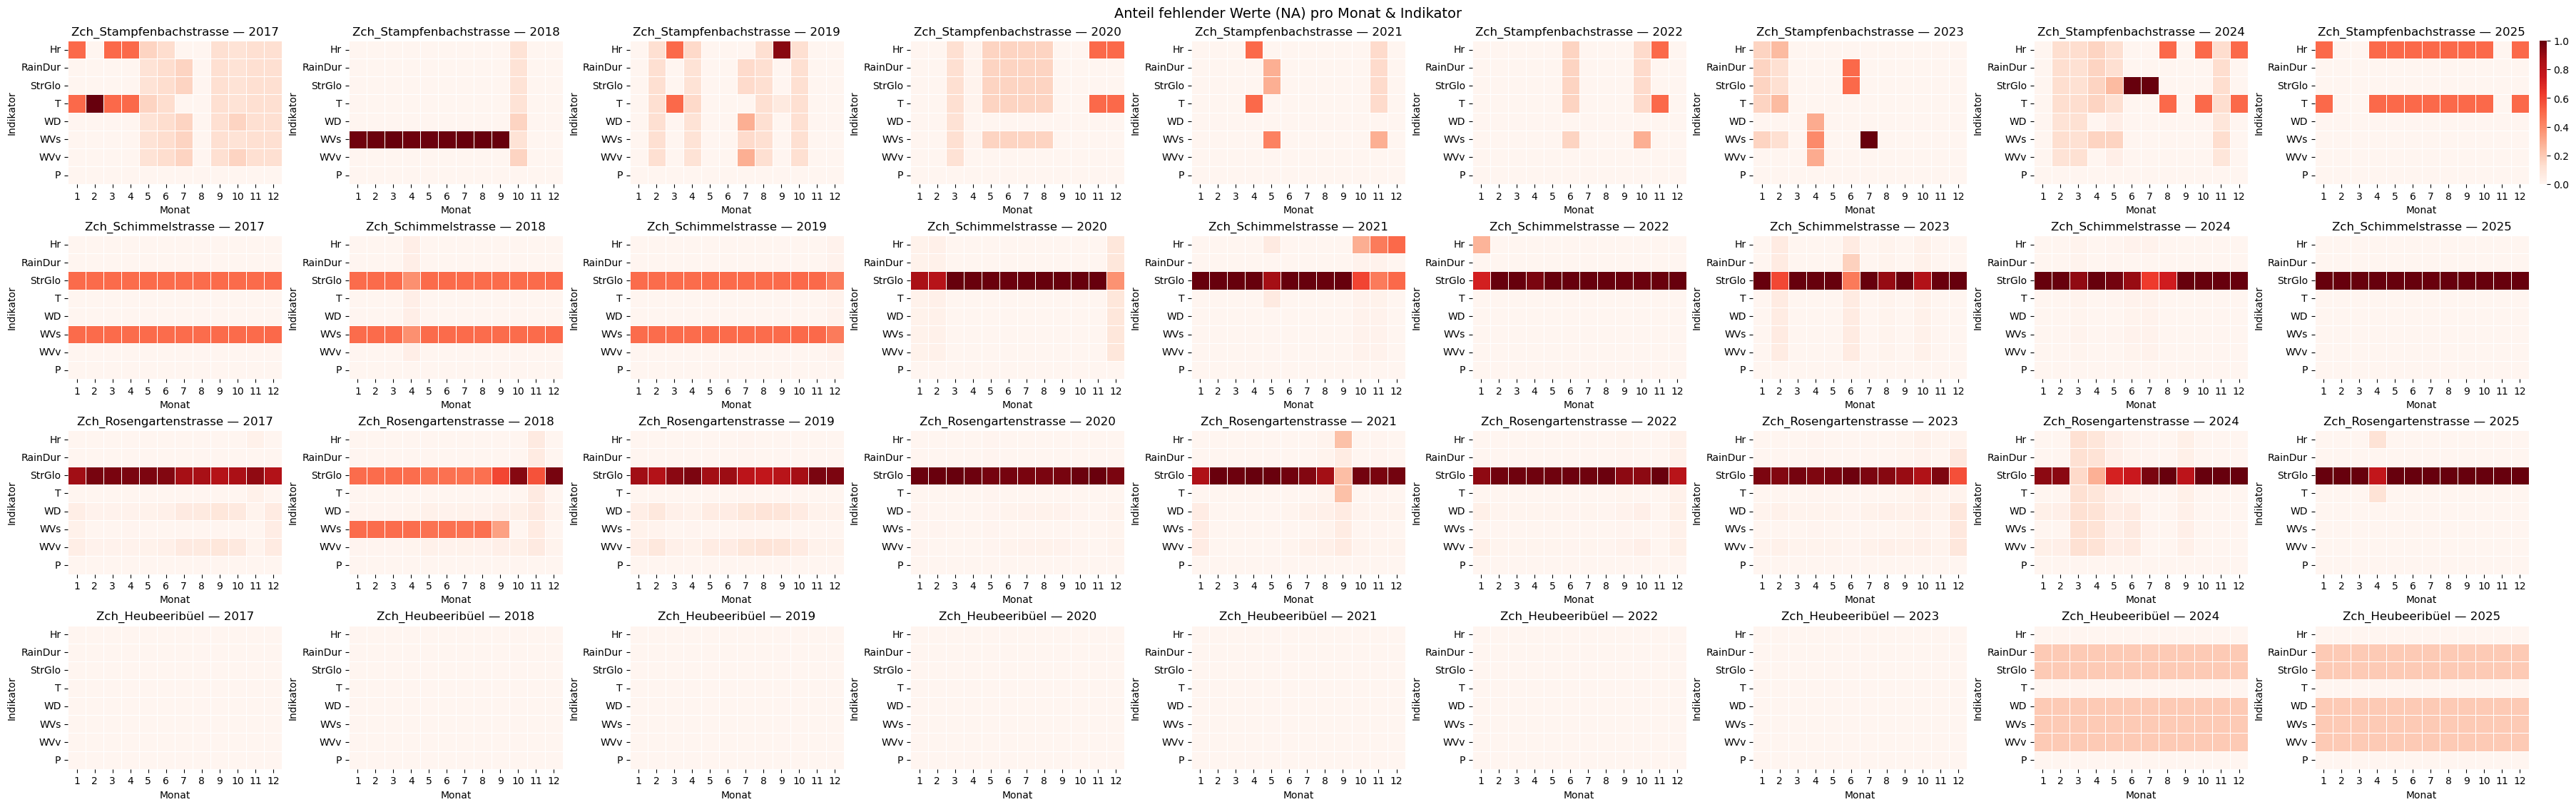

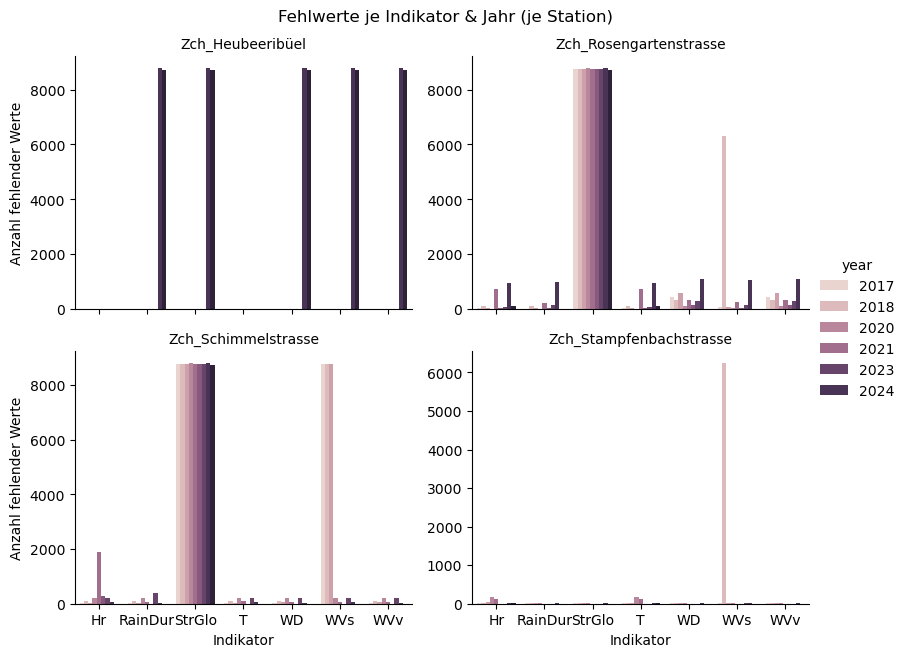

In [15]:
# =========================
# 1) Build a tidy 'missing' table
# =========================
key_cols = [c for c in ["Standort", "Datum_date", "Datum_time"] if c in df_meteo_pivot.columns]
parameters_cols = [c for c in df_meteo_pivot.columns if c not in key_cols]
# Melt to long format: one row per (keys, Parameter), with value column 'Wert'
long_vals = df_meteo_pivot.melt(
    id_vars=key_cols,
    value_vars=parameters_cols,
    var_name="Parameter",
    value_name="Wert"
)

# Keep only rows where the pollutant value is missing
na_long = long_vals[long_vals["Wert"].isna()].drop(columns="Wert").reset_index(drop=True)


# Choose your parameters & stations
PARAMS = ["Hr", "RainDur", "StrGlo", "T", "WD", "WVs", "WVv", "P"]  # adjust to taste
stations_all = na_long["Standort"].unique().tolist()
STATIONS5 = stations_all[:4]  # or explicitly pick the four you want

# Prepare year/month
na_long["date_ts"] = pd.to_datetime(na_long["Datum_date"], errors="coerce")
na_long["year"] = na_long["date_ts"].dt.year
na_long["month"] = na_long["date_ts"].dt.month

# Filter to desired subset
miss_sub = na_long[na_long["Standort"].isin(STATIONS5) & na_long["Parameter"].isin(PARAMS)].copy()

# 1) Monthly heatmap: missing rate per (station, year, month, parameter)
# We need denominators (how many expected rows per month) — in a daily matrix it’s one per day, in hourly 24/day.
# Using `mean` of boolean is fine if your pivot has one row per day; if hourly, it is fraction of hours missing in that month.

monthly_rate = (
    miss_sub.groupby(["Standort", "year", "month", "Parameter"], dropna=True)
            .size()                              # count of missing entries
            .reset_index(name="missing_count")
)

# To get rates, we need total expected entries per (station, year, month, parameter).
# If the pivot is daily with one row per day per station, total days per month:
days_per_month = (
    na_long.groupby(["Standort", "year", "month"])
           .size()
           .reset_index(name="total_rows_month")  # total rows across all params; we'll assume same for each param
)

monthly_rate = monthly_rate.merge(days_per_month, on=["Standort", "year", "month"], how="left")
monthly_rate["missing_rate"] = monthly_rate["missing_count"] / monthly_rate["total_rows_month"]

# Fill in missing combinations to show zeros in the heatmap
full_index = pd.MultiIndex.from_product(
    [STATIONS5, sorted(miss_sub["year"].dropna().unique()), range(1,13), PARAMS],
    names=["Standort", "year", "month", "Parameter"]
).to_frame(index=False)

monthly_rate = full_index.merge(monthly_rate,
                                on=["Standort", "year", "month", "Parameter"],
                                how="left").fillna({"missing_rate": 0.0})

# Plot grid: rows = stations, cols = years
years_sorted = sorted(monthly_rate["year"].unique())
nrows, ncols = len(STATIONS5), len(years_sorted)
fig, axes = plt.subplots(nrows=nrows, ncols=ncols,
                         figsize=(4*ncols, 2.8*nrows), constrained_layout=True)

# Ensure axes is 2D
if nrows == 1 and ncols == 1:
    axes = np.array([[axes]])
elif nrows == 1:
    axes = axes.reshape(1, -1)

for i, st in enumerate(STATIONS5):
    for j, yr in enumerate(years_sorted):
        ax = axes[i, j]
        mat = (
            monthly_rate[(monthly_rate["Standort"] == st) & (monthly_rate["year"] == yr)]
            .pivot(index="Parameter", columns="month", values="missing_rate")
            .reindex(index=PARAMS)
        )
        sns.heatmap(mat, ax=ax, vmin=0, vmax=1, cmap="Reds",
                    cbar=(i==0 and j==ncols-1), linewidths=0.5, linecolor="white")
        ax.set_title(f"{st} — {yr}")
        ax.set_xlabel("Monat")
        ax.set_ylabel("Indikator")
        ax.set_xticklabels([str(m) for m in range(1, 13)], rotation=0)

fig.suptitle("Anteil fehlender Werte (NA) pro Monat & Indikator", fontsize=14)
plt.show()

# 2) Grouped bar chart: counts per pollutant per station, hue = year
counts = (
    miss_sub.groupby(["Standort", "Parameter", "year"], dropna=True)
            .size()
            .reset_index(name="missing_count")
)

g = sns.catplot(
    data=counts, x="Parameter", y="missing_count", hue="year", col="Standort",
    kind="bar", col_wrap=2, sharey=False, height=3.2, aspect=1.3
)
g.set_titles("{col_name}")
g.set_axis_labels("Indikator", "Anzahl fehlender Werte")
plt.suptitle("Fehlwerte je Indikator & Jahr (je Station)", y=1.02)
plt.show()

In [16]:
# check time during summer time
df_meteo.loc[df_meteo['Datetime'].dt.date == pd.to_datetime('2024-06-18').date(), 'Datetime']

1412227   2024-06-18 00:00:00+01:00
1412228   2024-06-18 00:00:00+01:00
1412229   2024-06-18 00:00:00+01:00
1412230   2024-06-18 00:00:00+01:00
1412231   2024-06-18 00:00:00+01:00
                     ...           
1412822   2024-06-18 23:00:00+01:00
1412823   2024-06-18 23:00:00+01:00
1412824   2024-06-18 23:00:00+01:00
1412825   2024-06-18 23:00:00+01:00
1412826   2024-06-18 23:00:00+01:00
Name: Datetime, Length: 600, dtype: datetime64[ns, UTC+01:00]

In [17]:
df_meteo_pivot.to_csv("data/meteodata_h1_17_24.csv", index=False)